# PRIM — Ambulance Pooling (fac=0, amb=1)

Find where T1 mortality > 0.


In [1]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RESULTS_PATH = _root / "data_cluster/saltelli_with_wrong_pooling_columns/results.csv"
df = pd.read_csv(RESULTS_PATH)
print(f"Loaded {len(df)} runs")

# ── PRIM CONFIGURATION ────────────────────────────────────────
PRIM_OUTCOME = "death_rate_T1_BCAS"  # <-- change to any outcome column
PRIM_THRESHOLD = 0.0                 # <-- mortality > this is "interesting"
PRIM_DIRECTION = "above"             # <-- "above" = outcome > threshold, "below" = outcome < threshold
# ─────────────────────────────────────────────────────────────

UNCERTAINTIES = ["ccp_r1_same_bn_min", "ccp_r1_inter_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"]

sub = df[(df["facility_eligibility"] == 0) & (df["ambulance_eligibility"] == 1)].reset_index(drop=True)
print(f"Policy: Ambulance Pooling (fac=0, amb=1), {len(sub)} runs")
print(f"T1 mortality range: {sub['death_rate_T1_BCAS'].min():.4f} - {sub['death_rate_T1_BCAS'].max():.4f}")
print(f"Nonzero: {(sub['death_rate_T1_BCAS'] > 0).sum()} / {len(sub)} ({(sub['death_rate_T1_BCAS'] > 0).mean():.1%})")


Loaded 98304 runs
Policy: Ambulance Pooling (fac=0, amb=1), 24576 runs
T1 mortality range: 0.0000 - 1.0000
Nonzero: 10763 / 24576 (43.8%)


# PRIM — Where is T1 mortality ZERO?


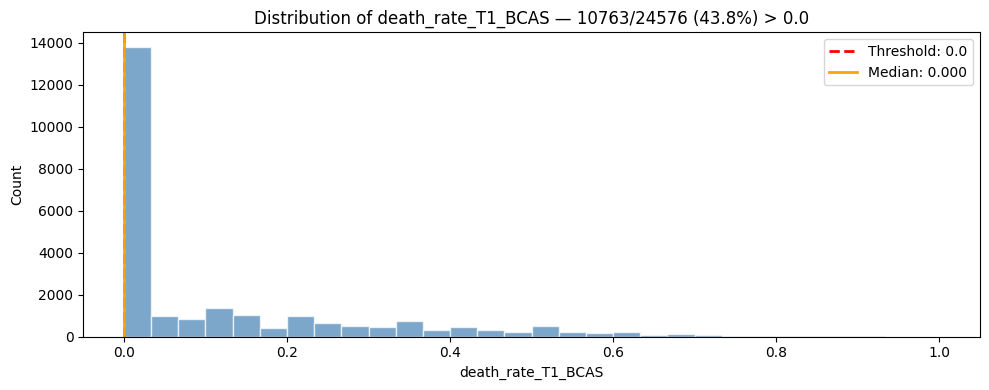

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
vals = sub[PRIM_OUTCOME].dropna()
ax.hist(vals, bins=30, color="steelblue", alpha=0.7, edgecolor="white")
ax.axvline(PRIM_THRESHOLD, color="red", linewidth=2, linestyle="--", label=f"Threshold: {PRIM_THRESHOLD}")
ax.axvline(vals.median(), color="orange", linewidth=2, label=f"Median: {vals.median():.3f}")
ax.set_xlabel(PRIM_OUTCOME)
ax.set_ylabel("Count")
direction_label = ">" if PRIM_DIRECTION == "above" else "<"
n_interest = (vals > PRIM_THRESHOLD).sum() if PRIM_DIRECTION == "above" else (vals < PRIM_THRESHOLD).sum()
ax.set_title(f"Distribution of {PRIM_OUTCOME} — {n_interest}/{len(vals)} ({n_interest/len(vals):.1%}) {direction_label} {PRIM_THRESHOLD}")
ax.legend()
plt.tight_layout()
plt.show()


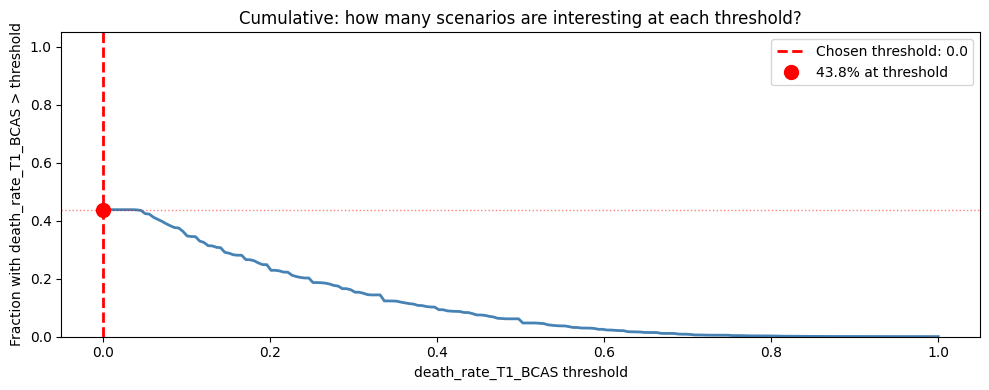

In [3]:
fig, ax = plt.subplots(figsize=(10, 4))
vals = sub[PRIM_OUTCOME].dropna().sort_values().values
thresholds = np.linspace(vals.min(), vals.max(), 200)
if PRIM_DIRECTION == "above":
    fracs = [(vals > t).mean() for t in thresholds]
    ylabel = f"Fraction with {PRIM_OUTCOME} > threshold"
else:
    fracs = [(vals < t).mean() for t in thresholds]
    ylabel = f"Fraction with {PRIM_OUTCOME} < threshold"
ax.plot(thresholds, fracs, color="steelblue", linewidth=2)
ax.axvline(PRIM_THRESHOLD, color="red", linewidth=2, linestyle="--", label=f"Chosen threshold: {PRIM_THRESHOLD}")
frac_at_thresh = (vals > PRIM_THRESHOLD).mean() if PRIM_DIRECTION == "above" else (vals < PRIM_THRESHOLD).mean()
ax.axhline(frac_at_thresh, color="red", linewidth=1, linestyle=":", alpha=0.5)
ax.plot(PRIM_THRESHOLD, frac_at_thresh, "ro", markersize=10, label=f"{frac_at_thresh:.1%} at threshold")
ax.set_xlabel(f"{PRIM_OUTCOME} threshold")
ax.set_ylabel(ylabel)
ax.set_title("Cumulative: how many scenarios are interesting at each threshold?")
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()


PRIM target: death_rate_T1_BCAS > 0.0
Cases of interest: 10763 / 24576 (43.8%)



Selected box (death_rate_T1_BCAS > 0.0):
coverage       0.115395
density        0.989641
id            32.000000
k           1242.000000
mass           0.051066
mean           0.989641
n           1255.000000
res_dim        5.000000
Name: 32, dtype: float64

                        box 32                                        
                           min        max       qp value      qp value
waves_per_day         1.000000   3.500000            NaN  1.157371e-46
wave_duration_min     1.000000  44.500000            NaN  1.240293e-21
bcas_rate             0.036068   0.069993  1.563267e-116           NaN
ccp_r1_same_bn_min   16.500000  20.000000   1.099805e-24           NaN
ccp_r1_inter_bn_min  21.500000  35.000000   3.295706e-03           NaN



[None]

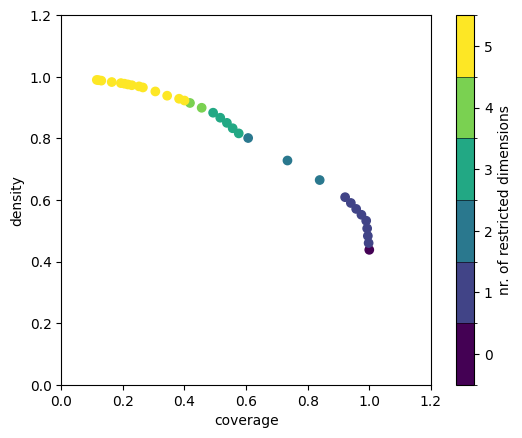

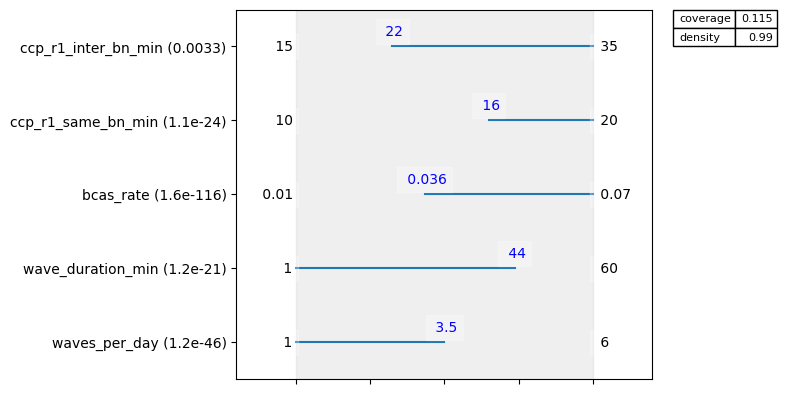

In [4]:
from ema_workbench.analysis import prim

x = sub[UNCERTAINTIES].astype(float)
if PRIM_DIRECTION == "above":
    y = sub[PRIM_OUTCOME].values > PRIM_THRESHOLD
    label = f"{PRIM_OUTCOME} > {PRIM_THRESHOLD}"
else:
    y = sub[PRIM_OUTCOME].values < PRIM_THRESHOLD
    label = f"{PRIM_OUTCOME} < {PRIM_THRESHOLD}"

print(f"PRIM target: {label}")
print(f"Cases of interest: {y.sum()} / {len(y)} ({y.mean():.1%})")

p = prim.Prim(x, y, threshold=0.5)
box = p.find_box()
box.show_tradeoff()
print()
print(f"Selected box ({label}):")
box.inspect(style="graph")
box.inspect()
